# Replanning campaign figures


# Campaign: plots from a saved run

Loads the receding-horizon campaign saved by `kristiansund_bridge_replanning.ipynb` (`results/campaign.pkl`, one `PlannerRun` per step), so the plots can be changed without re-running the simulation. Re-run `kristiansund_bridge_replanning.ipynb` to refresh the file.

In [1]:

import matplotlib.pyplot as plt
import numpy as np

from risk_informed_planner.experiment import PlannerRun
from risk_informed_planner.visualization import *

# written by the save cell right after the simulation loop in kristiansund_bridge_replanning.ipynb
runs = PlannerRun.load_many("results/campaign.pkl")
t_starts = np.concatenate([[0.0], np.cumsum([r.t_computation for r in runs])])
for k, r in enumerate(runs):
    print(f"step {k:02d}: starts at t = {t_starts[k]:6.1f} s, planned in {r.t_computation:5.1f} s, "
          f"path of {len(r.path or [])} nodes")

step 00: starts at t =    0.0 s, planned in  15.7 s, path of 19 nodes
step 01: starts at t =   15.7 s, planned in  15.2 s, path of 21 nodes
step 02: starts at t =   30.9 s, planned in  14.4 s, path of 19 nodes


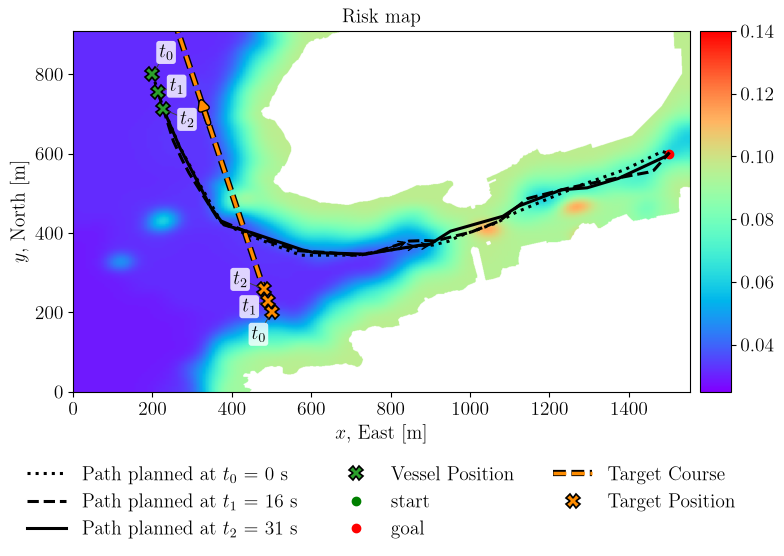

In [2]:
# Up to three available steps, over the risk heatmap of step 0:
# the path planned at each step (one line style per step), and where the own
# vessel and the other vessel were when that plan started (tagged t_k).
steps = tuple(range(min(3, len(runs))))
cfg = runs[0].cfg
save_prefix = f"campaign_alpha_{cfg.ALPHA}_beta_{cfg.BETA}_steps_0-{steps[-1]}_"

panels = plot_campaign_overlay(
    runs,
    steps=steps,
    background_step=0,
    metrics=("risk"),
    latex=True,
    vmin={"risk": 0.025, "collision": 0.05, "grounding": 0.25},
    vmax={"risk": 0.14, "collision": 0.2, "grounding": 0.4},
    figsize={"risk": (8, 7), "collision": (4.5, 4), "grounding": (4.5, 4)},
    fontsize={"risk": 14, "collision": 11, "grounding": 11},
    legend={"collision": False, "grounding": False},
    axis_labels={"collision": False, "grounding": False},
    legend_rows=3,
)

# Optional: explain points of the step-0 risk map (see kristiansund_bridge_figures.ipynb).
# annotate_hazard_drivers(panels, points=[dict(xy=(400.0, 500.0), inset_xy=(700.0, 250.0), label="A")], fontsize=11)

save_paper_panels(panels, save_dir="plots/campaign", save_prefix=save_prefix)